### code to translate German to English and vice versa with deepL

In [15]:
import pandas as pd
from pprint import pprint
import os
import ast
import deepl
import json
import requests
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
# get connection to deepl api
deepl_key = open("/Users/sofiaromero/Documents/DeepL.txt").read()
deepl_client = deepl.DeepLClient(deepl_key)

In [3]:
# api functions 

def generate_glossaries(dict_path_l, s_lang, t_lang, auth_key):
    url = "https://api-free.deepl.com/v3/glossaries"
    header= {
        "Authorization": f"DeepL-Auth-Key {auth_key}",
        "User-Agent": "YourApp/1.2.3",
        "Content-Type": "application/json"
    }    
    glossaries = []
    for i,d in enumerate(dict_path_l):
        payload = {
            "name": f"glossary{i}",
            "dictionaries": [{
                # TODO: get languages from file name
                "source_lang": s_lang,
                "target_lang": t_lang,
                "entries": open(d,"r").read(),
                "entries_format": "csv"}
            ]}
        resp = requests.post(url, headers=header, json=payload)
        print(resp.status_code, resp.json())
        glossaries.append(resp.json())
    return glossaries


def get_glossary_ids(auth_key):
    url = "https://api-free.deepl.com/v3/glossaries"
    headers = {
        "Authorization": f"DeepL-Auth-Key {auth_key}",
        "User-Agent": "YourApp/1.2.3",
    }
    resp = requests.get(url, headers=headers, timeout=30)
    print(resp.status_code)
    return [x.get("glossary_id") for x in resp.json()["glossaries"]]


def transalate_to(text_l, s_lang, t_lang, glossary_id):
    res = []
    for text in text_l:
        if glossary_id:
            res.append(deepl_client.translate_text(text, target_lang=t_lang, source_lang=s_lang, glossary=glossary_id).text)
        else: 
            res.append(deepl_client.translate_text(text, target_lang=t_lang, source_lang=s_lang).text)
    return res


In [4]:
#generate_glossaries(["config_files/ger_to_eng.csv"], "DE", "EN", deepl_key)
# get all current glossaries
glossary_ids = get_glossary_ids(deepl_key)

200


In [5]:
# translate ki terms as test
'''
test_terms = list(ast.literal_eval(open("config_files/ger_anthroscore_KI_terms.txt").read()).values())
print(test_terms)
translations = transalate_to(test_terms, "DE", "EN-GB", glossary_ids[0])
print(translations)
'''

'\ntest_terms = list(ast.literal_eval(open("config_files/ger_anthroscore_KI_terms.txt").read()).values())\nprint(test_terms)\ntranslations = transalate_to(test_terms, "DE", "EN-GB", glossary_ids[0])\nprint(translations)\n'

In [6]:
# write text (from file) and its transaltion to df and save to csv and json file
def tranlate_to_df(txts_json, file_to):
    # load json as dict
    with open(txts_json, "r") as f:
        txts = json.load(f)

    res_df = pd.DataFrame([(key, var) for (key, L) in txts.items() for var in L], columns=['id', 'text']).drop_duplicates(subset=['text']).reset_index(drop=True)
    #fill df with traslations
    res_df['translation'] = transalate_to(res_df['text'].tolist(), "DE", "EN-GB", glossary_ids[0]) # TODO: changing source and target langs dependeing on input
    #save to file 
    res_df.to_csv(f"{file_to}.csv", index=False)
    res_df.to_json(f"{file_to}.json", orient="records")
    return res_df


### Translate KI_sentences to English

In [8]:
tranlate_to_df("generated_data/KI_sentences.json", "generated_data/KI_sentences_translated")

QuotaExceededException: Quota for this billing period has been exceeded, message: Quota Exceeded

In [21]:
# input to anthroscore
# get AI-related words, sorted according to 'Häufigkeitsklassen' and from AnthroScore
# https://corpora.uni-leipzig.de/de/res?corpusId=deu_news_2024&word=KI
ki_terms = list(ast.literal_eval(open("config_files/ger_anthroscore_KI_terms.txt").read()).values())
ki_terms += ['KI','Künstliche Intelligenz', 'ChatGPT', 'AI', 'Copilot', 'Gemini', 'Chatbot','LLM', 'Chat-GPT',
            'Sprachmodell', 'KI-Modell', 'KI-System', 'KI-Tool', 'Artificial Intelligence', 'KI-Anwendung']
ai_terms = transalate_to(ki_terms, "DE", "EN-GB", glossary_ids[0])

QuotaExceededException: Quota for this billing period has been exceeded, message: Quota exceeded

In [46]:
with open(f"config_files/ai_terms.txt", "w") as f:
        f.writelines([" "+x for x in ai_terms])
        f.close()

with open(f"config_files/ki_terms.txt", "w") as f:
        f.writelines([" "+x for x in ki_terms])
        f.close()

In [ ]:
# anthroscore for translated (english) sentences
ai_terms = open(f"config_files/ai_terms.txt", "r").read()
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated_scores.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/anthroscore_results.csv --text_id_name id '''
terminal_input

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities  palm lms llama transformer Language models Language model gpt plms pre-trained language models gpt-2 xlnet large language models llms gpt-3 Foundation model gpt-neo gpt-j chatgpt gpt-4 AI Artificial intelligence ChatGPT AI Copilot Gemini Chatbot LLM Chat GPT Language model AI model AI system AI tool Artificial Intelligence AI application --output_file generated_data/anthroscore_results.csv --text_id_name id '

In [ ]:
# anthroscore for german sentences
ki_terms = open(f"config_files/ki_terms.txt", "r").read()
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_text_scores.csv --text_column_name translation --entities {ki_terms} --output_file generated_data/KI_sentences_text_scores_ger_terms.csv --text_id_name id '''
terminal_input_ger

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities  palm lms llama Transformer Sprachmodelle Sprachmodell gpt plms vortrainierte Sprachmodelle gpt-2 xlnet große Sprachmodelle llms gpt-3 Stiftungsmodell gpt-neo gpt-j chatgpt gpt-4 KI Künstliche Intelligenz ChatGPT AI Copilot Gemini Chatbot LLM Chat-GPT Sprachmodell KI-Modell KI-System KI-Tool Artificial Intelligence KI-Anwendung --output_file generated_data/KI_sentences_text_scores_ger_terms.csv --text_id_name id '

#### AntroScore Results

In [ ]:
#delete duplicate sentences
text_scores = pd.read_csv(f"generated_data/KI_sentences_text_scores_palm.csv")#.drop_duplicates(subset=['sentence']).reset_index(drop=True)
translated_scores =  pd.read_csv(f"generated_data/KI_sentences_translated_scores_palm.csv")#.drop_duplicates(subset=['sentence']).reset_index(drop=True)

translated_scores.head()

,Unnamed: 0,sentence,masked_sentence,text_id,POS,verb,original_term,original_noun,anthroscore
0,0,palm recycled paper a beig,<mask> a beig,_5774798.txt,8206900633647566924,paper,palm,palm recycled paper,0.796555
1,1,you now want to exercise sole control over gpt,you now want to exercise sole control over <mask>,_1825405.txt,439,over,gpt,gpt,0.441902
2,2,you now want to exercise sole control over gpt,you now want to exercise sole control over <mask>,_1825405.txt,439,over,GPT,gpt,0.441902
3,3,palm recycled paper a beig,<mask> a beig,_5571102.txt,8206900633647566924,paper,palm,palm recycled paper,0.796555
4,4,headmaster philipp palm speaks of individual c...,<mask> of individual cases that are exaggerate...,_851884.txt,429,see,palm,headmaster philipp palm speaks,-0.931421


ger: count    884.000000
mean       0.662053
std        1.833044
min       -5.876325
25%        0.045020
50%        0.805898
75%        1.269159
max        6.024401
Name: anthroscore, dtype: float64
-------------------
eng: count    1887.000000
mean       -0.830208
std         2.524370
min        -8.127385
25%        -2.815646
50%        -0.679761
75%         0.796555
max         9.124494
Name: anthroscore, dtype: float64


ValueError: x and y must be the same size

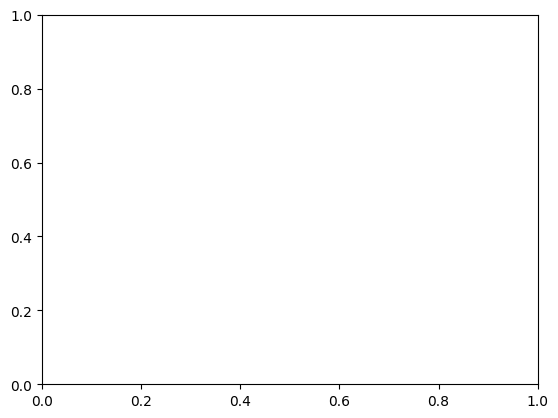

In [44]:
# plot score distributions, compare languages
ger_results = text_scores["anthroscore"]
eng_results = translated_scores["anthroscore"]
max_len = max([len(eng_results), len(ger_results)])
print("ger:",ger_results.describe())
print("-------------------")
print("eng:",eng_results.describe())

#plt.plot(ger_results)
#plt.plot(eng_results, color = 'hotpink')

plt.scatter(ger_results, eng_results)

In [61]:
#print(text_scores.head())
ger_grouped = text_scores.groupby(["original_term"])#text_scores["anthroscore"]
ger_mean = ger_grouped["anthroscore"].mean()

eng_grouped = translated_scores.groupby(["original_term"])#text_scores["anthroscore"]
eng_mean = eng_grouped["anthroscore"].mean()

print("ger:",ger_mean)
print("-------------------")
print("eng:",eng_mean)


ger: original_term
AI              0.533996
Artificial      0.495856
Chat            1.832408
ChatGPT         1.039946
Chatbot         1.121539
Copilot         0.920569
GPT            -0.917521
Gemini          1.017331
Intelligence    0.959324
Language        0.933544
chatgpt         1.039946
gpt            -0.917521
intelligence    0.959324
language        0.933544
llama           1.400988
palm            0.832589
system          1.400282
transformer     0.967429
Name: anthroscore, dtype: float64
-------------------
eng: original_term
AI              0.096338
Artificial     -1.902706
Chat           -3.971190
ChatGPT        -2.544142
Chatbot        -1.298129
Copilot         3.975721
Foundation     -2.767267
GPT            -1.755609
Gemini         -1.122534
Intelligence   -1.942242
Language       -0.973121
application    -4.164199
chatgpt        -2.544142
gpt            -1.755609
intelligence   -1.942242
language       -0.973121
large          -1.402135
llama           0.326794
model   